In [2]:
# Project setup and imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings

# DATA VISUALIZATIONS

### 1. BASIC DATA EXPLORATION & DATA CLEANING

In [3]:
# Load the dataset
df = pd.read_csv('data.csv')

In [4]:
print(f"\nDataset Shape: {df.shape}")
print(f"\nColumn Names:\n{df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head())
print(f"\nData Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")


Dataset Shape: (569, 33)

Column Names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

First few rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.

In [5]:
# Remove columns that are entirely NaN or have too many missing values
print("\n[CLEANING DATA]")
initial_shape = df.shape
df = df.dropna(axis=1, how='all')  # Drop columns with all NaN
print(f"Dropped columns with all NaN values: {initial_shape[1] - df.shape[1]} columns")

# Remove 'Unnamed' columns that are often artifacts
unnamed_cols = [col for col in df.columns if 'Unnamed' in col]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)
    print(f"Dropped unnamed columns: {unnamed_cols}")

# Remove 'id' column if present (not useful for analysis)
if 'id' in df.columns:
    df = df.drop('id', axis=1)
    print("Dropped 'id' column")

print(f"\nCleaned Dataset Shape: {df.shape}")
print(f"\nRemaining Missing Values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")

print(f"\nBasic Statistics:\n{df.describe()}")


[CLEANING DATA]
Dropped columns with all NaN values: 1 columns
Dropped 'id' column

Cleaned Dataset Shape: (569, 31)

Remaining Missing Values:
Series([], dtype: int64)

Basic Statistics:
       radius_mean  texture_mean  perimeter_mean    area_mean  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799       

### 2. TARGET VARIABLE ANALYSIS

In [6]:
print(df['diagnosis'].value_counts())
print(f"\nPercentages:\n{df['diagnosis'].value_counts(normalize=True) * 100}")

diagnosis
B    357
M    212
Name: count, dtype: int64

Percentages:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


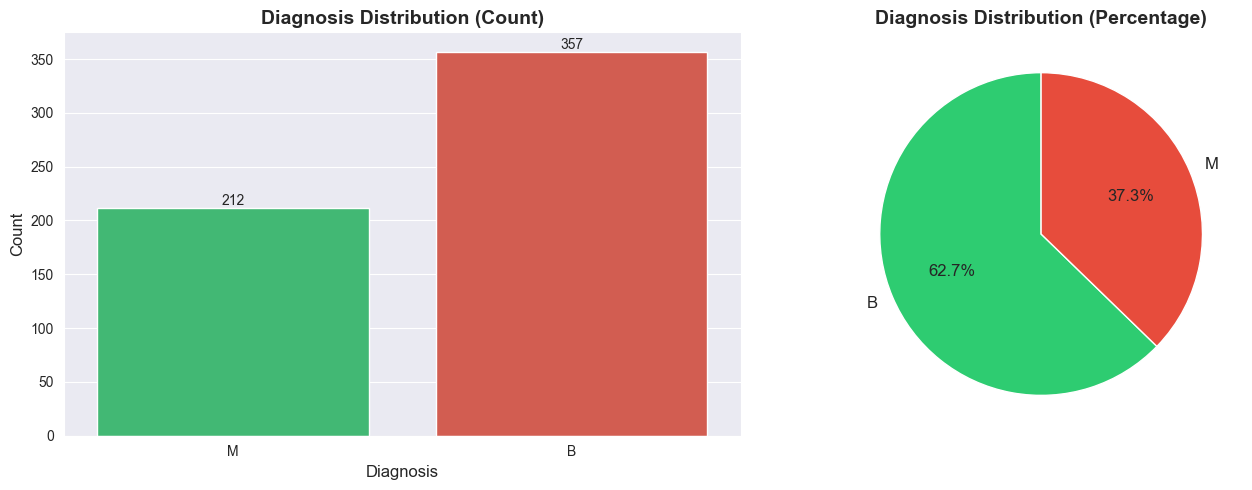

In [7]:
# Plot 1: Diagnosis Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(data=df, x='diagnosis', palette=['#2ecc71', '#e74c3c'], hue='diagnosis', ax=axes[0])
axes[0].set_title('Diagnosis Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
for container in axes[0].containers:
    axes[0].bar_label(container)

# Pie chart
diagnosis_counts = df['diagnosis'].value_counts()
colors = ['#2ecc71', '#e74c3c']
axes[1].pie(diagnosis_counts, labels=diagnosis_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Diagnosis Distribution (Percentage)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 3. FEATURE ANALYSIS - Mean Features

In [8]:
# Get mean features (columns ending with _mean)
mean_features = [col for col in df.columns if 'mean' in col.lower()]
print(f"\nAnalyzing features: {mean_features}")


Analyzing features: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean']


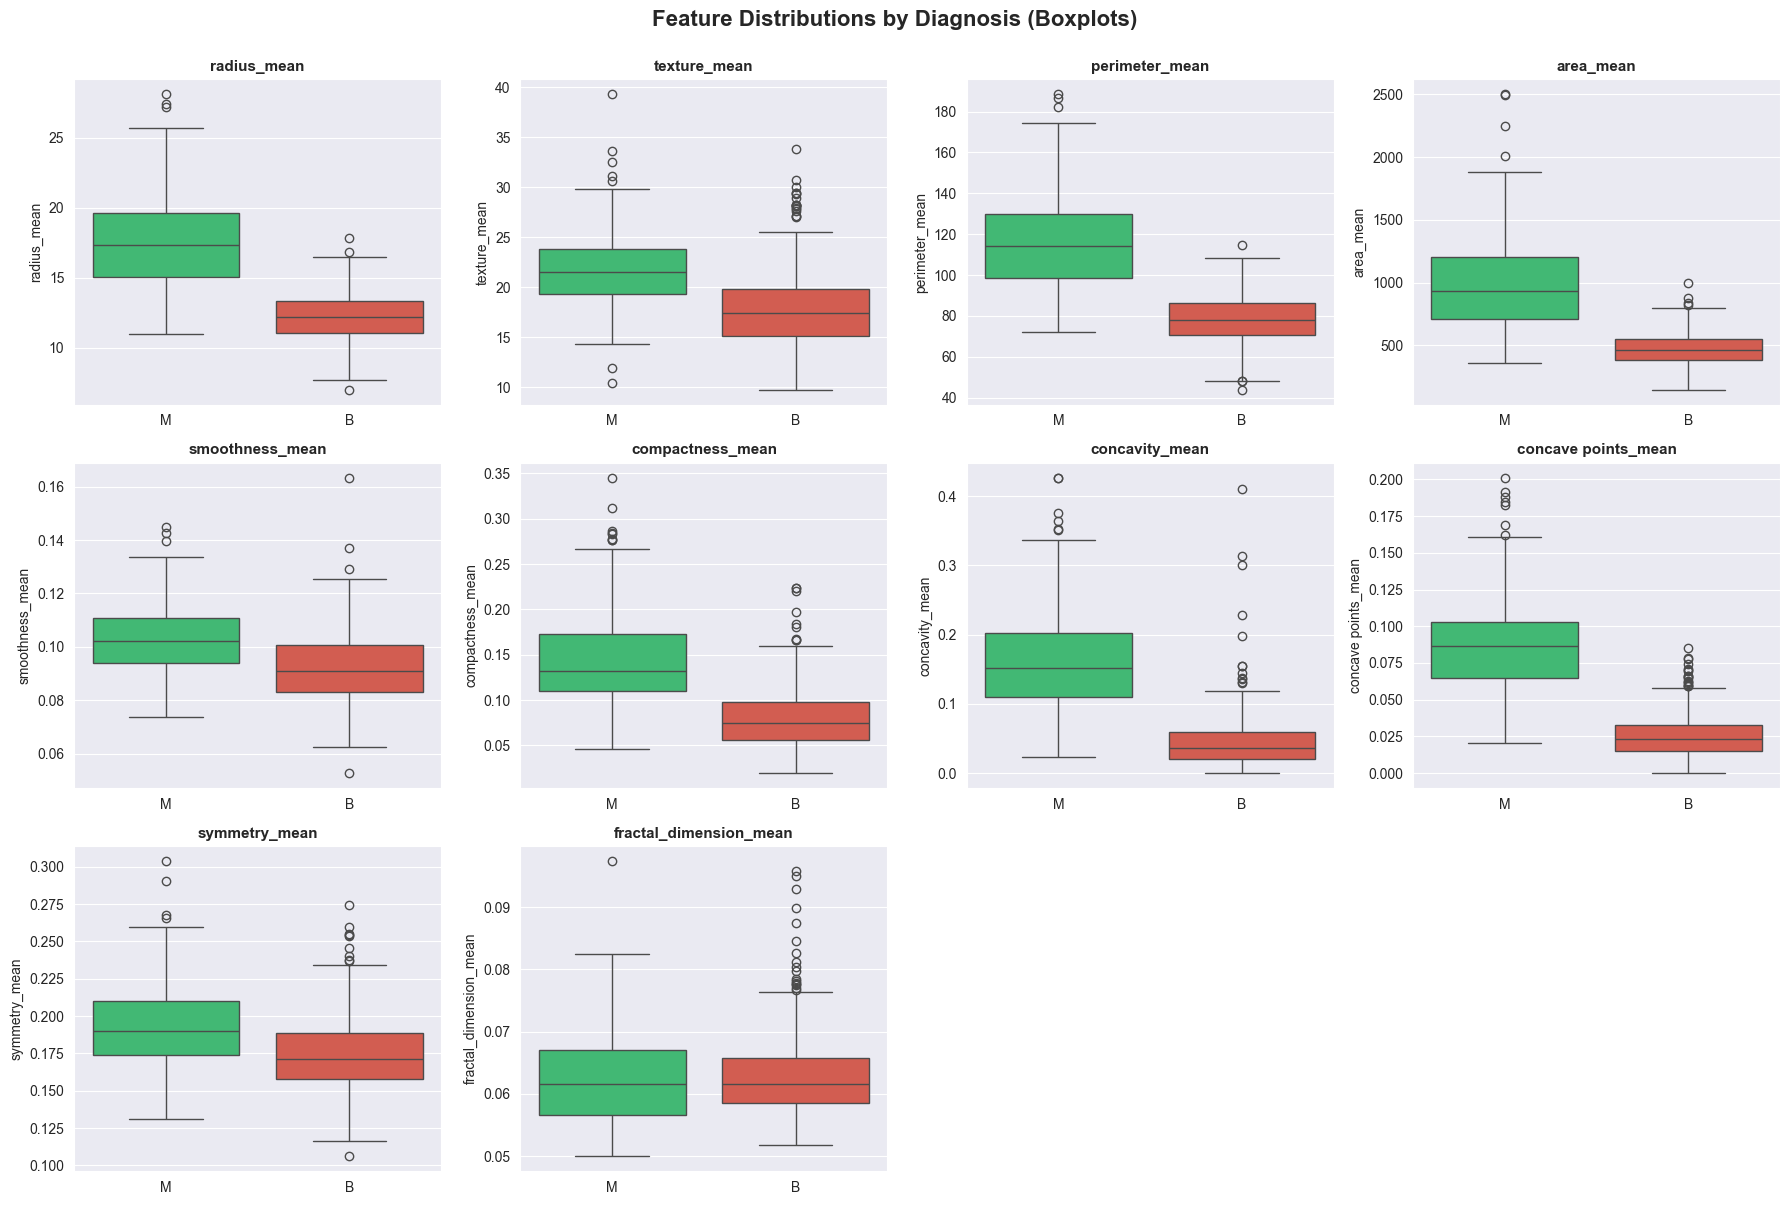

In [9]:
# Plot 2: Distribution of Mean Features by Diagnosis
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.ravel()

for idx, feature in enumerate(mean_features[:12]):
    if feature in df.columns:
        sns.boxplot(data=df, x='diagnosis', y=feature, palette=['#2ecc71', '#e74c3c'], ax=axes[idx], hue='diagnosis')
        axes[idx].set_title(f'{feature}', fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('')

# Remove empty subplots
for idx in range(len(mean_features), 12):
    fig.delaxes(axes[idx])

plt.suptitle('Feature Distributions by Diagnosis (Boxplots)', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

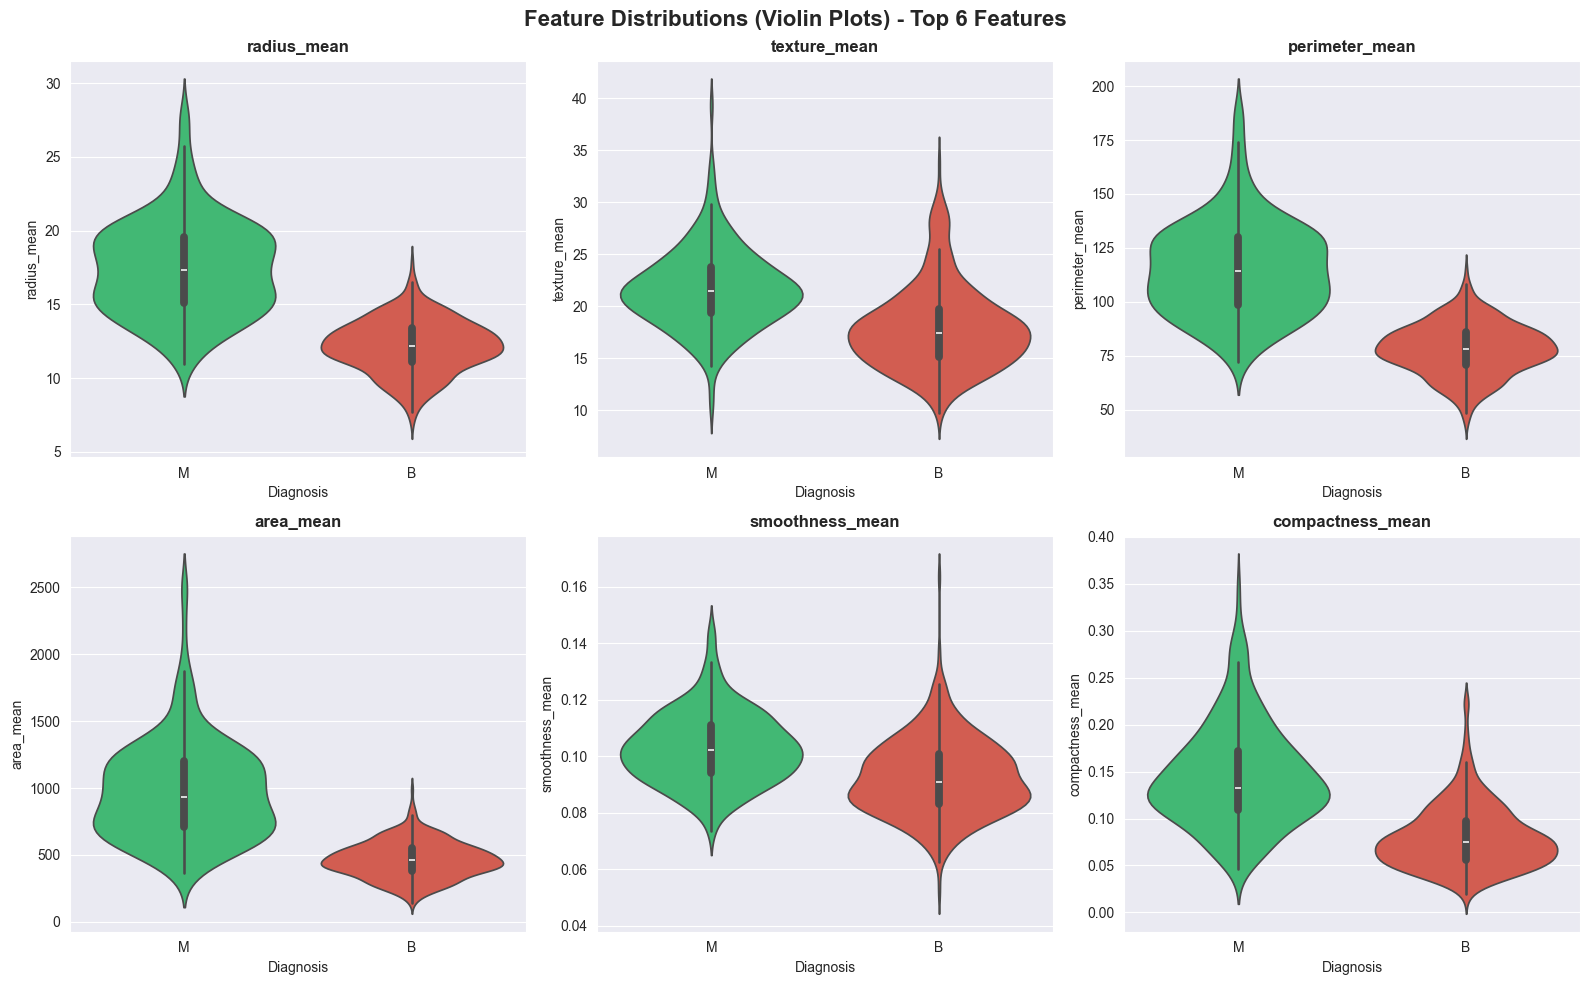

In [10]:
# Plot 3: Violin plots for top features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, feature in enumerate(mean_features[:6]):
    if feature in df.columns:
        sns.violinplot(data=df, x='diagnosis', y=feature, palette=['#2ecc71', '#e74c3c'],
                      ax=axes[idx], inner='box', hue='diagnosis')
        axes[idx].set_title(f'{feature}', fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Diagnosis', fontsize=10)

plt.suptitle('Feature Distributions (Violin Plots) - Top 6 Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 4. CORRELATION ANALYSIS

In [11]:
# Prepare numeric data
numeric_df = df.select_dtypes(include=[np.number])
numeric_df.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

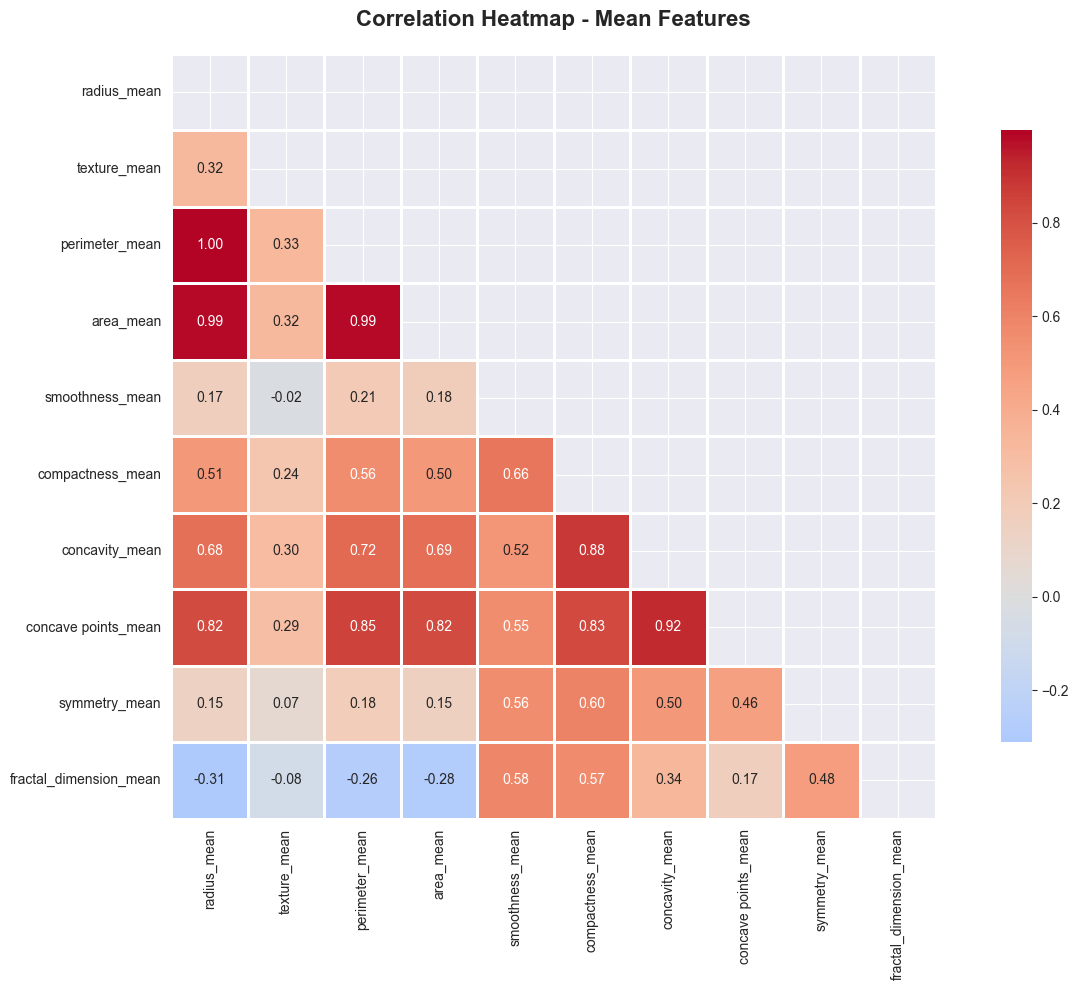

In [12]:
# Plot 4: Correlation Heatmap (Mean features only for clarity)
mean_numeric_cols = [col for col in numeric_df.columns if 'mean' in col.lower()]

plt.figure(figsize=(14, 10))
correlation_matrix = numeric_df[mean_numeric_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap - Mean Features', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [13]:
# Find strongly and weakly correlated features
strong_correlations_pairs = []
weak_correlations_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.8:
            strong_correlations_pairs.append((correlation_matrix.columns[i],
                                   correlation_matrix.columns[j],
                                   correlation_matrix.iloc[i, j]))
        if abs(correlation_matrix.iloc[i, j]) < 0.2:
            weak_correlations_pairs.append((correlation_matrix.columns[i],
                                   correlation_matrix.columns[j],
                                   correlation_matrix.iloc[i, j]))

strong_correlations_pairs.sort(key=lambda x: x[2], reverse=True)
weak_correlations_pairs.sort(key=lambda x: x[2])

print("\nTop 10 Strongly Correlated Feature Pairs (|corr| > 0.8):")
for feat1, feat2, corr in strong_correlations_pairs[:10]:
    print(f"  {feat1} <-> {feat2}: {corr:.3f}")

print("\nTop 10 Weakly Correlated Feature Pairs (|corr| < 0.2):")
for feat1, feat2, corr in weak_correlations_pairs[:10]:
    print(f"  {feat1} <-> {feat2}: {corr:.3f}")


Top 10 Strongly Correlated Feature Pairs (|corr| > 0.8):
  radius_mean <-> perimeter_mean: 0.998
  radius_mean <-> area_mean: 0.987
  perimeter_mean <-> area_mean: 0.987
  concavity_mean <-> concave points_mean: 0.921
  compactness_mean <-> concavity_mean: 0.883
  perimeter_mean <-> concave points_mean: 0.851
  compactness_mean <-> concave points_mean: 0.831
  area_mean <-> concave points_mean: 0.823
  radius_mean <-> concave points_mean: 0.823

Top 10 Weakly Correlated Feature Pairs (|corr| < 0.2):
  texture_mean <-> fractal_dimension_mean: -0.076
  texture_mean <-> smoothness_mean: -0.023
  texture_mean <-> symmetry_mean: 0.071
  radius_mean <-> symmetry_mean: 0.148
  area_mean <-> symmetry_mean: 0.151
  concave points_mean <-> fractal_dimension_mean: 0.167
  radius_mean <-> smoothness_mean: 0.171
  area_mean <-> smoothness_mean: 0.177
  perimeter_mean <-> symmetry_mean: 0.183


### 5. PCA VISUALIZATION

In [14]:
# Prepare data for PCA - ensure no NaN values
X = numeric_df.values
y = df['diagnosis'].map({'M': 1, 'B': 0}).values

print(f"\nData shape for PCA: {X.shape}")

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"\nExplained Variance Ratio: {pca.explained_variance_ratio_}")
print(f"Total Variance Explained: {sum(pca.explained_variance_ratio_)*100:.2f}%")


Data shape for PCA: (569, 30)

Explained Variance Ratio: [0.44272026 0.18971182]
Total Variance Explained: 63.24%


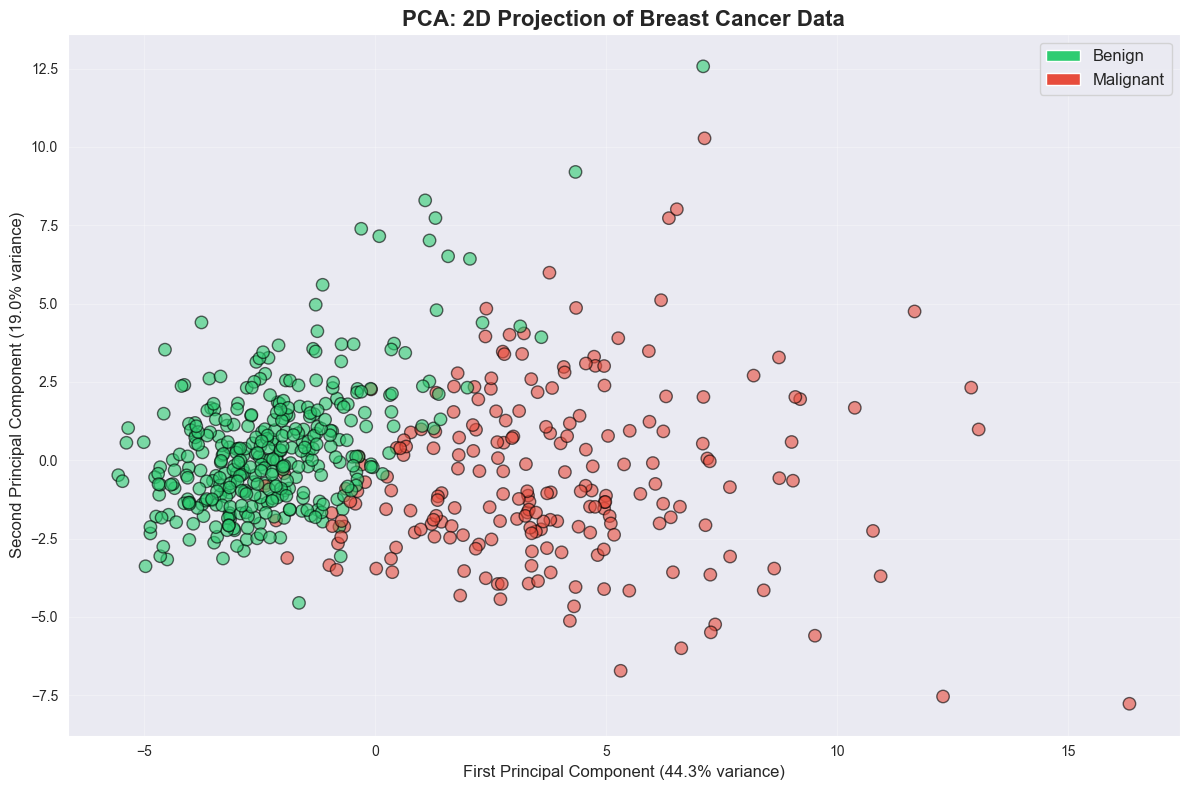

In [15]:
# Plot 5: PCA Scatter Plot
plt.figure(figsize=(12, 8))
colors = ['#2ecc71' if label == 0 else '#e74c3c' for label in y]
labels = ['Benign' if label == 0 else 'Malignant' for label in y]

scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.6, s=80, edgecolors='black')
plt.xlabel(f'First Principal Component ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
plt.ylabel(f'Second Principal Component ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
plt.title('PCA: 2D Projection of Breast Cancer Data', fontsize=16, fontweight='bold')
plt.grid(alpha=0.3)

# Create legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', label='Benign'),
                   Patch(facecolor='#e74c3c', label='Malignant')]
plt.legend(handles=legend_elements, loc='best', fontsize=12)
plt.tight_layout()
plt.show()

### 6. PAIRPLOT FOR TOP FEATURES


Creating pairplot for: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']


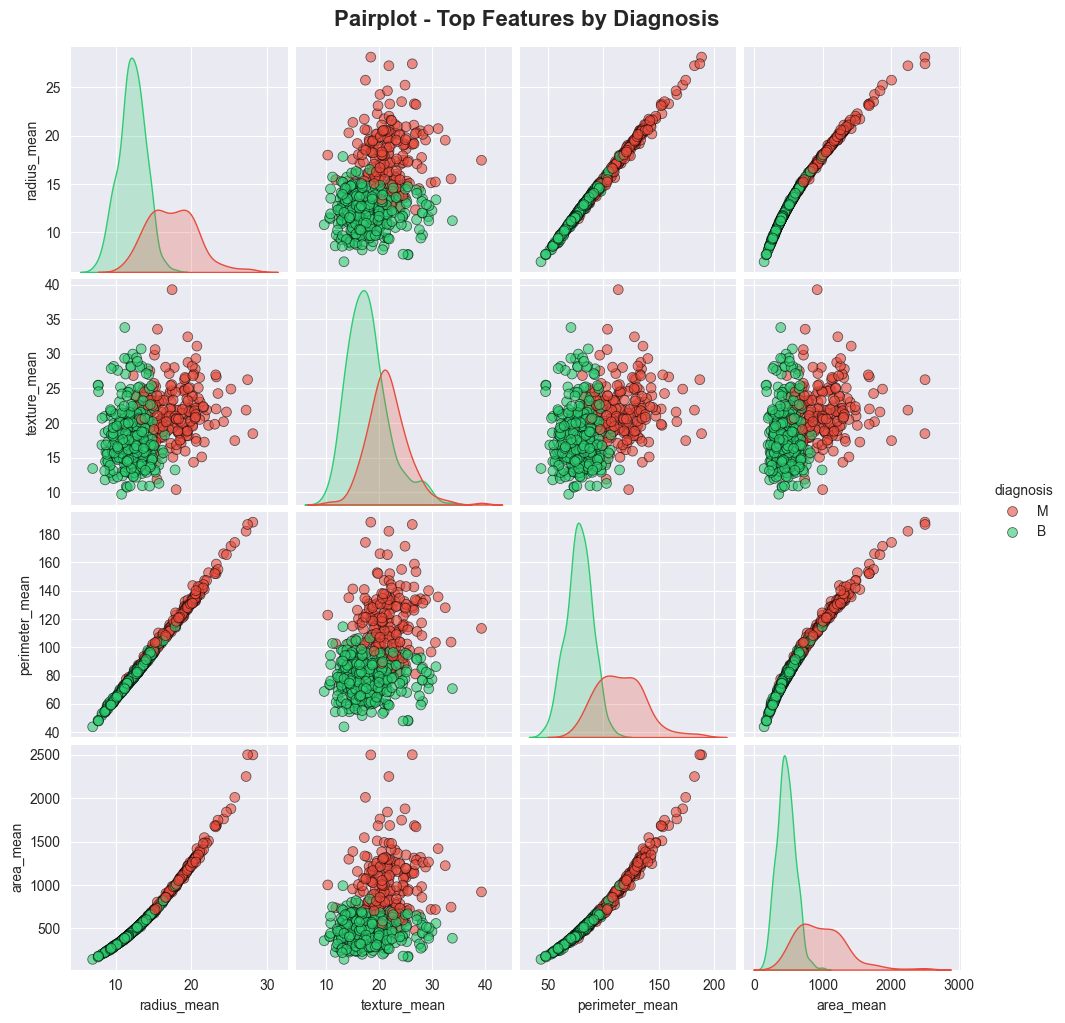

In [16]:
# Select top 4 most important features for pairplot (to keep it readable)
top_features = mean_features[:4] if len(mean_features) >= 4 else mean_features
pairplot_df = df[top_features + ['diagnosis']].copy()

print(f"\nCreating pairplot for: {top_features}")

# Plot 6: Pairplot
pairplot = sns.pairplot(pairplot_df, hue='diagnosis', palette={'B': '#2ecc71', 'M': '#e74c3c'},
                        diag_kind='kde', plot_kws={'alpha': 0.6, 's': 50, 'edgecolor': 'black'},
                        height=2.5)
pairplot.figure.suptitle('Pairplot - Top Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.show()

### 7. FEATURE IMPORTANCE PREVIEW (Statistical)

In [17]:
# Calculate mean difference between classes for each feature
feature_importance = {}
for col in mean_features:
    if col in df.columns:
        benign_mean = df[df['diagnosis'] == 'B'][col].mean()
        malignant_mean = df[df['diagnosis'] == 'M'][col].mean()
        difference = abs(malignant_mean - benign_mean)
        feature_importance[col] = difference

# Sort by importance
sorted_features = sorted(feature_importance.items(), key=lambda x: x[1], reverse=True)

print("\nTop 10 Features by Mean Difference:")
for idx, (feature, importance) in enumerate(sorted_features[:10], 1):
    print(f"{idx}. {feature}: {importance:.4f}")


Top 10 Features by Mean Difference:
1. area_mean: 515.5862
2. perimeter_mean: 37.2900
3. radius_mean: 5.3163
4. texture_mean: 3.6901
5. concavity_mean: 0.1147
6. compactness_mean: 0.0651
7. concave points_mean: 0.0623
8. symmetry_mean: 0.0187
9. smoothness_mean: 0.0104
10. fractal_dimension_mean: 0.0002


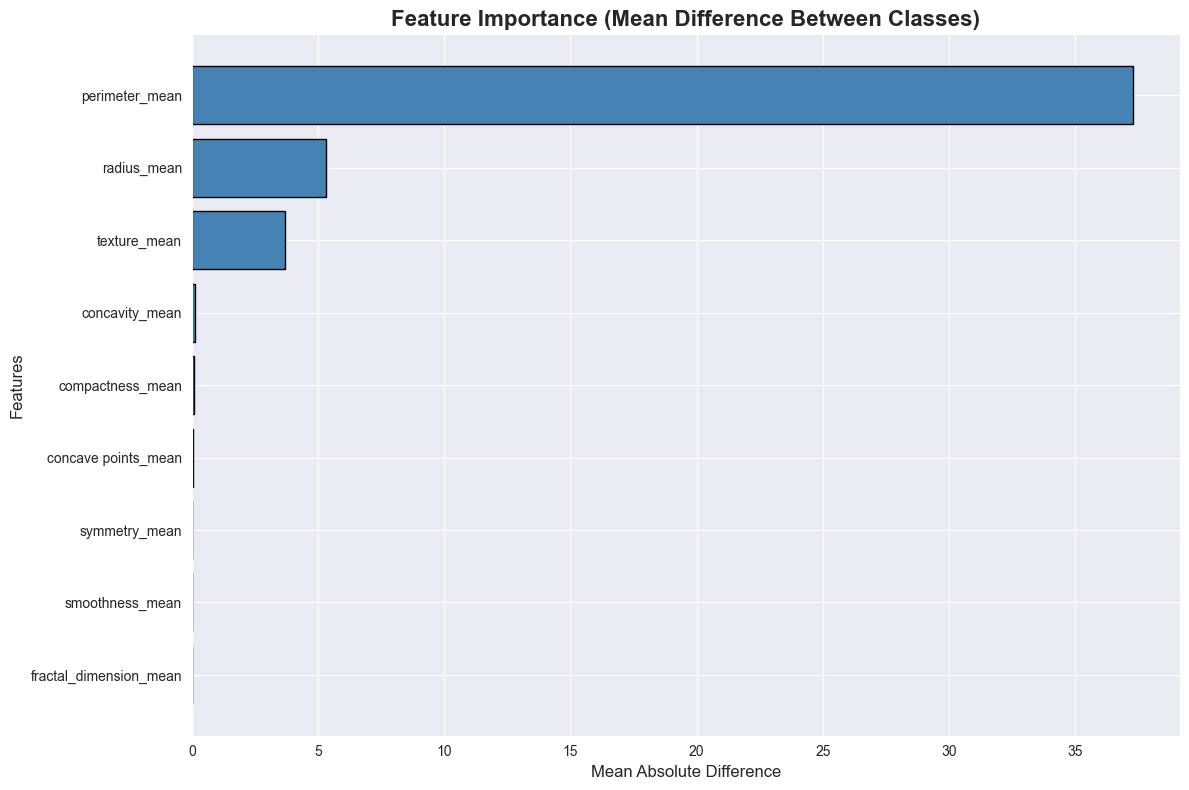

In [18]:
# Plot 7: Feature Importance Bar Plot
plt.figure(figsize=(12, 8))
sorted_features.remove(sorted_features[0])
features = [x[0] for x in sorted_features[:10]]
importances = [x[1] for x in sorted_features[:10]]

plt.barh(features, importances, color='steelblue', edgecolor='black')
plt.xlabel('Mean Absolute Difference', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Importance (Mean Difference Between Classes)', fontsize=16, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# MODELS TRAINING

### 1. LOAD AND PREPARE DATA

In [19]:
df = pd.read_csv('data.csv')

In [20]:
# Remove columns that are entirely NaN or have too many missing values
print("\n[CLEANING DATA]")
initial_shape = df.shape
df = df.dropna(axis=1, how='all')  # Drop columns with all NaN
print(f"Dropped columns with all NaN values: {initial_shape[1] - df.shape[1]} columns")

# Remove 'Unnamed' columns that are often artifacts
unnamed_cols = [col for col in df.columns if 'Unnamed' in col]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)
    print(f"Dropped unnamed columns: {unnamed_cols}")

# Remove 'id' column if present (not useful for analysis)
if 'id' in df.columns:
    df = df.drop('id', axis=1)
    print("Dropped 'id' column")

# Prepare features and target
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Encode target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # M=1, B=0
print(f"\nLabel encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")


[CLEANING DATA]
Dropped columns with all NaN values: 1 columns
Dropped 'id' column

Label encoding: {'B': np.int64(0), 'M': np.int64(1)}


### 2. TRAIN-TEST SPLIT & SCALING

In [21]:
print("\n[2] SPLITTING DATA (70% train, 30% test)...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

# Standardize features (crucial for SVM)
print("\n[3] STANDARDIZING FEATURES...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_scaled = scaler.fit_transform(X)  # For clustering


[2] SPLITTING DATA (70% train, 30% test)...
Training set: (398, 30)
Test set: (171, 30)

[3] STANDARDIZING FEATURES...


### 3. SVM MODEL TRAINING

In [22]:
# Train baseline SVM
svm_baseline = SVC(kernel='rbf', random_state=42, probability=True)
svm_baseline.fit(X_train_scaled, y_train)

# Baseline predictions
y_pred_baseline = svm_baseline.predict(X_test_scaled)
y_proba_baseline = svm_baseline.predict_proba(X_test_scaled)[:, 1]

print("\n--- BASELINE SVM RESULTS ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_baseline):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_baseline):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_baseline):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_baseline):.4f}")


--- BASELINE SVM RESULTS ---
Accuracy: 0.9591
Precision: 1.0000
Recall: 0.8906
F1-Score: 0.9421
ROC-AUC: 0.9972


In [23]:
# Hyperparameter Tuning with GridSearchCV
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}

grid_search = GridSearchCV(
    SVC(random_state=42, probability=True),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train_scaled, y_train)

print(f"\nBest Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

svm_best = grid_search.best_estimator_

# Predictions with boosted model
y_pred_best = svm_best.predict(X_test_scaled)
y_proba_best = svm_best.predict_proba(X_test_scaled)[:, 1]

print("\n--- OPTIMIZED SVM RESULTS ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_best):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_best):.4f}")


Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross-Validation Score: 0.9722

--- OPTIMIZED SVM RESULTS ---
Accuracy: 0.9708
Precision: 0.9836
Recall: 0.9375
F1-Score: 0.9600
ROC-AUC: 0.9955


In [24]:
# Cross-validation scores
cv_scores = cross_val_score(svm_best, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"CV Scores: {cv_scores}")
print(f"Mean CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

CV Scores: [0.9875     1.         0.9875     0.96202532 0.92405063]
Mean CV Score: 0.9722 (+/- 0.0541)


### 4. SVM VISUALIZATION

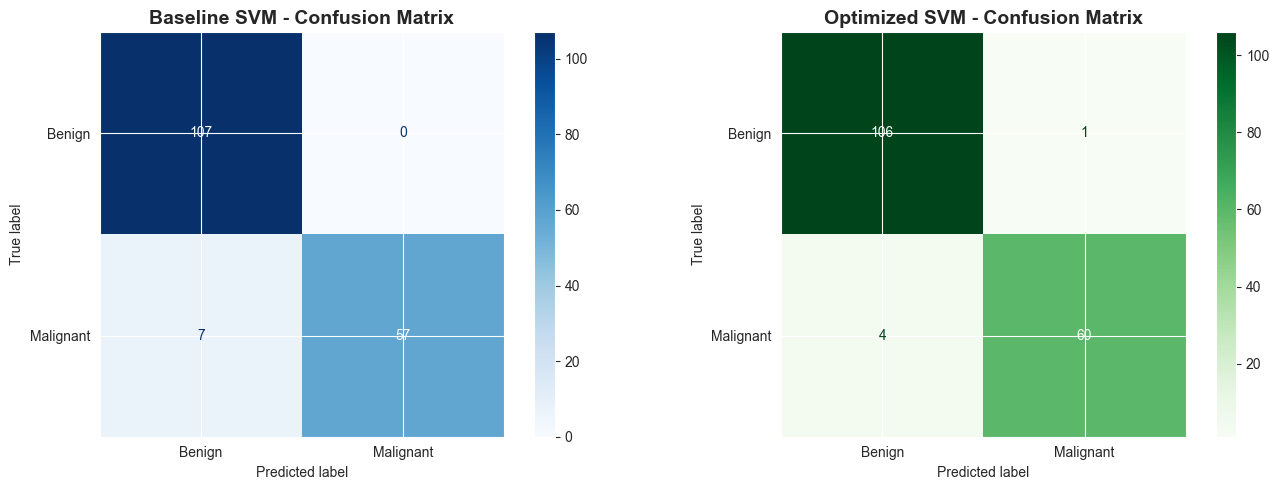

In [25]:
# Plot 1: Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_baseline = confusion_matrix(y_test, y_pred_baseline)
cm_best = confusion_matrix(y_test, y_pred_best)

ConfusionMatrixDisplay(cm_baseline, display_labels=['Benign', 'Malignant']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Baseline SVM - Confusion Matrix', fontsize=14, fontweight='bold')

ConfusionMatrixDisplay(cm_best, display_labels=['Benign', 'Malignant']).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Optimized SVM - Confusion Matrix', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

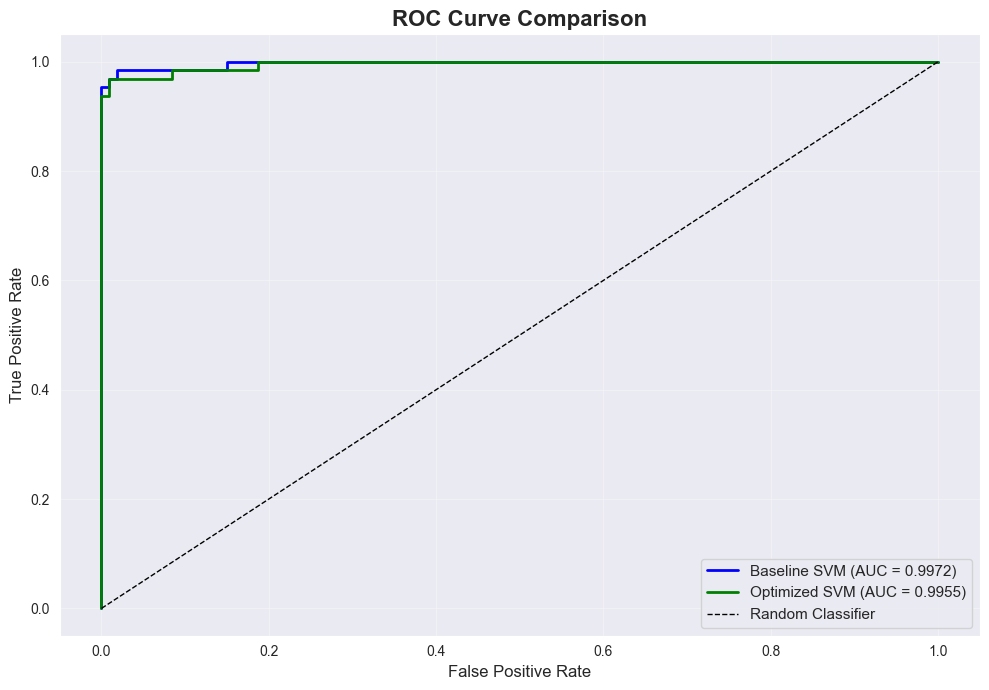

In [26]:
# Plot 2: ROC Curve
plt.figure(figsize=(10, 7))

# Baseline ROC
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_proba_baseline)
roc_auc_baseline = roc_auc_score(y_test, y_proba_baseline)

# Optimized ROC
fpr_best, tpr_best, _ = roc_curve(y_test, y_proba_best)
roc_auc_best = roc_auc_score(y_test, y_proba_best)

plt.plot(fpr_baseline, tpr_baseline, label=f'Baseline SVM (AUC = {roc_auc_baseline:.4f})',
         linewidth=2, color='blue')
plt.plot(fpr_best, tpr_best, label=f'Optimized SVM (AUC = {roc_auc_best:.4f})',
         linewidth=2, color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=1)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison', fontsize=16, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Plot 3: Classification Report Heatmap
print(classification_report(y_test, y_pred_best, target_names=['Benign', 'Malignant']))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.98       107
   Malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### 5. CLUSTERING ANALYSIS (UNSUPERVISED)

In [28]:
# Use PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_)*100:.2f}%")


[8] APPLYING PCA FOR VISUALIZATION...
Explained variance: [0.44272026 0.18971182]
Total variance explained: 63.24%


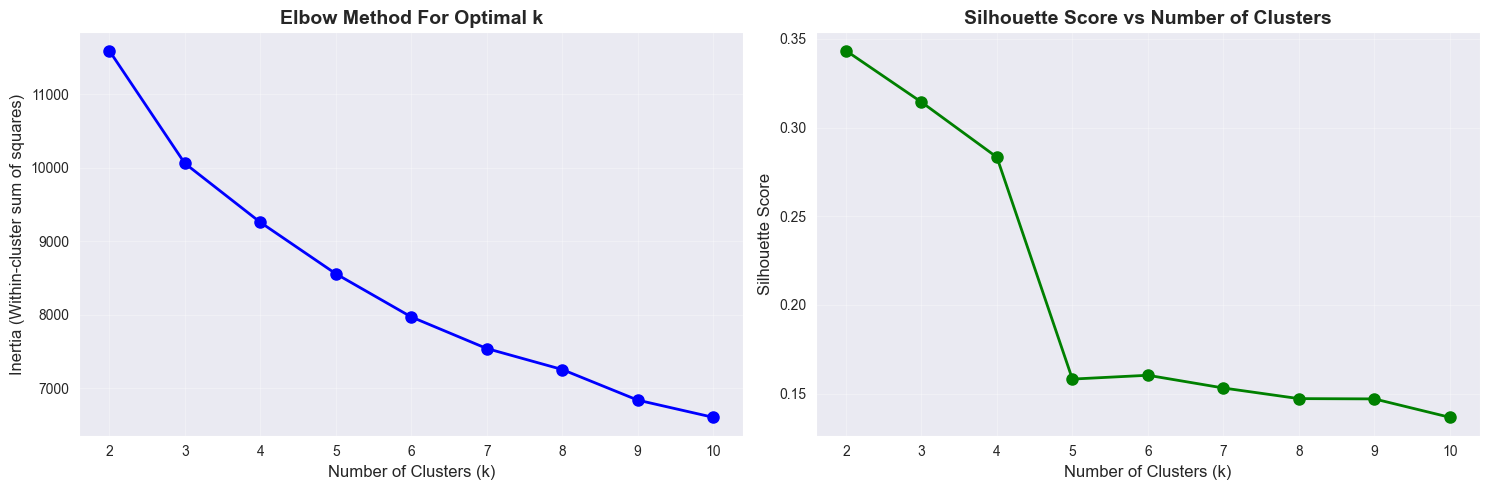

In [31]:
# Find optimal number of clusters using elbow method
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans_temp.labels_))

# Plot Elbow Method
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[0].set_ylabel('Inertia (Within-cluster sum of squares)', fontsize=12)
axes[0].set_title('Elbow Method For Optimal k', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3)

axes[1].plot(K_range, silhouette_scores, 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[1].set_ylabel('Silhouette Score', fontsize=12)
axes[1].set_title('Silhouette Score vs Number of Clusters', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# Apply K-Means with k=2 (since we have 2 diagnosis classes)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print(f"\nK-Means (k=2) Results:")
print(f"Silhouette Score: {silhouette_score(X_scaled, kmeans_labels):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_scaled, kmeans_labels):.4f}")
print(f"Calinski-Harabasz Score: {calinski_harabasz_score(X_scaled, kmeans_labels):.4f}")

# Compare with true labels
print(f"\nCluster distribution: {np.bincount(kmeans_labels)}")
print(f"True label distribution: {np.bincount(y_encoded)}")


K-Means (k=2) Results:
Silhouette Score: 0.3434
Davies-Bouldin Index: 1.3205
Calinski-Harabasz Score: 267.6917

Cluster distribution: [375 194]
True label distribution: [357 212]


In [34]:
# 5B. Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=2, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_scaled)

print(f"\nHierarchical Clustering Results:")
print(f"Silhouette Score: {silhouette_score(X_scaled, hierarchical_labels):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_scaled, hierarchical_labels):.4f}")
print(f"Calinski-Harabasz Score: {calinski_harabasz_score(X_scaled, hierarchical_labels):.4f}")


[10] HIERARCHICAL CLUSTERING...

Hierarchical Clustering Results:
Silhouette Score: 0.3394
Davies-Bouldin Index: 1.3700
Calinski-Harabasz Score: 248.6288
